In [ ]:
# Import pandas and matplotlib
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Read the raw transaction CSV into a DataFrame
df = pd.read_csv("../data/raw/paysim.csv")
df.to_parquet("../data/paysim.parquet")
print(df.shape)
print(df.dtypes)
df.head()

(6362620, 11)
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
# Count missing values in each column
df.isna().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [ ]:
# Count repeated rows using all columns
df.duplicated().sum()

np.int64(0)

In [ ]:
# isFraud is binary: 1 means fraud and 0 means legitimate
# Its mean gives the fraction of transactions labelled fraud
fraud_rate = df["isFraud"].mean()
print(f"Fraud rate: {fraud_rate:.4%}")

# Number of fraud cases: sum counts the 1s
fraud_count = df["isFraud"].sum()
print(f"Fraud cases: {fraud_count:,}")

Fraud rate: 0.1291%
Fraud cases: 8,213


In [ ]:
# Compare transaction volume and fraud prevalence across transaction types
df.groupby("type")["isFraud"].agg( transaction_count="count",
    fraud_count="sum",
    fraud_rate="mean")

,transaction_count,fraud_count,fraud_rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.001840
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.007688


In [ ]:
# Inspect the earliest and latest simulation steps to help assess how transaction activity changes over time
print("First step:", df["step"].min())
print("Last step:", df["step"].max())

fraud_by_step = (df.groupby("step")["isFraud"].agg(transaction_count="count", fraud_count="sum")
)

fraud_by_step.head()

First step: 1
Last step: 743


,transaction_count,fraud_count
step,,
1,2708,16
2,1014,8
3,552,4
4,565,10
5,665,6


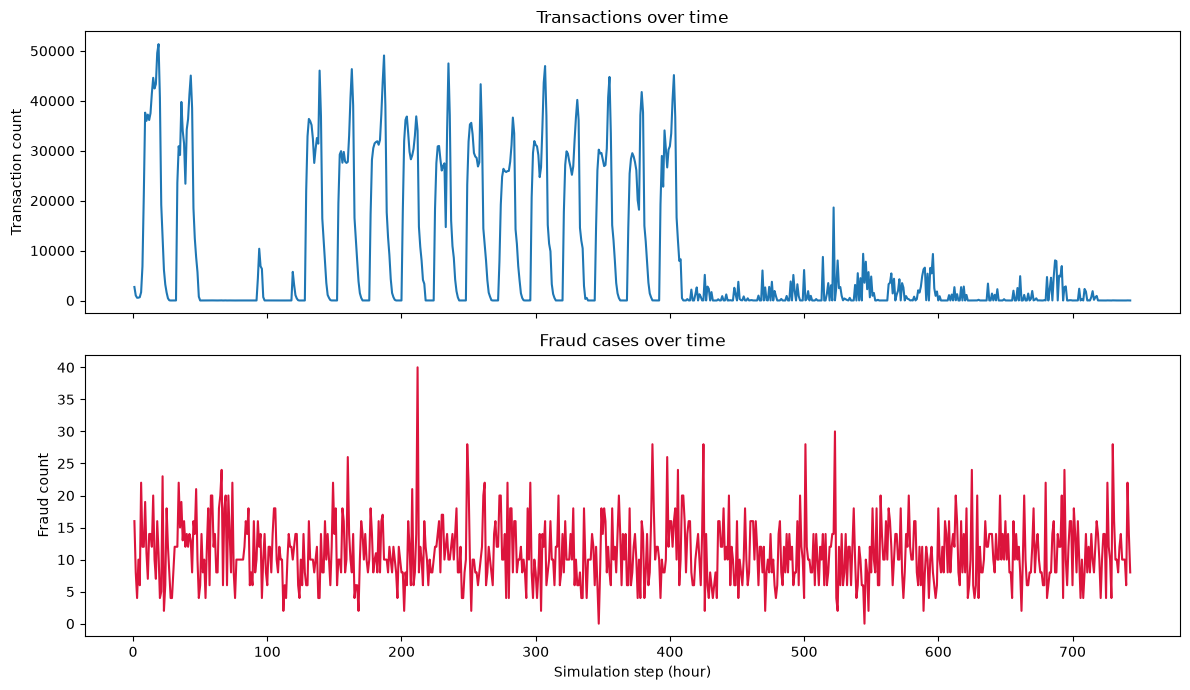

In [ ]:
# Plot transaction counts and fraud counts in separate panels
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(fraud_by_step.index, fraud_by_step["transaction_count"])
axes[0].set_title("Transactions over time")
axes[0].set_ylabel("Transaction count")

axes[1].plot(
    fraud_by_step.index,
    fraud_by_step["fraud_count"],
    color="crimson"
)
axes[1].set_title("Fraud cases over time")
axes[1].set_ylabel("Fraud count")
axes[1].set_xlabel("Simulation step (hour)")

plt.tight_layout()
plt.show()

In [11]:
# Fraud rate before and after step 400
df.assign(after_400=df["step"] > 400).groupby("after_400")["isFraud"].agg(["count", "sum", "mean"])

,count,sum,mean
after_400,,,
False,5787030,4477,0.000774
True,575590,3736,0.006491


In [ ]:
# Count transactions and fraud cases within each block
# This checks whether the class distribution changes over time
time_summary = (
    df.assign(time_block=((df["step"] - 1) // 100) * 100 + 1)
    .groupby("time_block")["isFraud"]
    .agg(transaction_count="count", fraud_count="sum")
)

time_summary["fraud_rate_pct"] = (
    time_summary["fraud_count"]
    / time_summary["transaction_count"]
    * 100
)

time_summary

,transaction_count,fraud_count,fraud_rate_pct
time_block,,,
1,1059516,1190,0.112315
101,1322666,1064,0.080444
201,1691468,1147,0.067811
301,1713380,1076,0.062800
401,274777,1084,0.394502
501,197240,1052,0.533360
601,92152,1110,1.204532
701,11421,490,4.290342


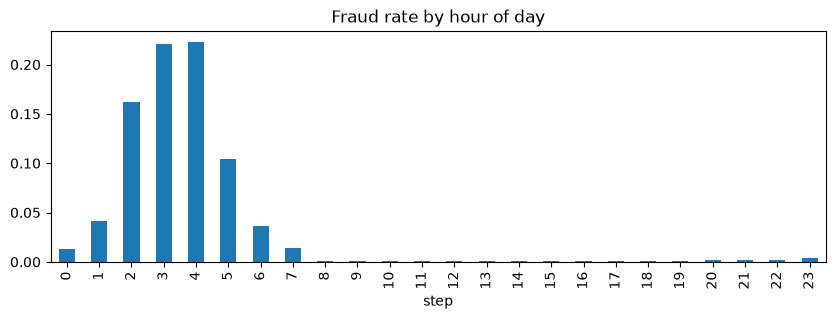

In [18]:
# Fraud rate by hour of day
hour = (df["step"] - 1) % 24
df.groupby(hour)["isFraud"].mean().plot(kind="bar", figsize=(10, 3), title="Fraud rate by hour of day")

import os
os.makedirs("../reports", exist_ok=True)
plt.savefig("../reports/fraud_rate_by_hour.png", dpi=150, bbox_inches="tight")

In [13]:
# Keep each simulation hour entirely within one split
train_df = df.loc[df["step"] <= 400]
val_df = df.loc[(df["step"] > 400) & (df["step"] <= 600)]
test_df = df.loc[df["step"] > 600]

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

split_summary = pd.DataFrame([
    {
        "split": name,
        "transactions": len(part),
        "fraud_cases": int(part["isFraud"].sum()),
        "fraud_rate_pct": part["isFraud"].mean() * 100,
        "first_step": part["step"].min(),
        "last_step": part["step"].max()
    }
    for name, part in splits.items()
]).set_index("split")

split_summary

,transactions,fraud_cases,fraud_rate_pct,first_step,last_step
split,,,,,
train,5787030,4477,0.077363,1,400
validation,472017,2136,0.452526,401,600
test,103573,1600,1.544804,601,743


In [ ]:
# Compare the existing rule's flags against the actual fraud labels
pd.crosstab(df["isFlaggedFraud"], df["isFraud"])

isFraud,0,1
isFlaggedFraud,,
0,6354407,8197
1,0,16


In [22]:
# Count correctly flagged fraud, false alarms and missed fraud.
tp = ((df["isFlaggedFraud"] == 1) & (df["isFraud"] == 1)).sum()
fp = ((df["isFlaggedFraud"] == 1) & (df["isFraud"] == 0)).sum()
fn = ((df["isFlaggedFraud"] == 0) & (df["isFraud"] == 1)).sum()

# Guard against division by zero if no alerts or fraud cases exist.
precision = tp / (tp + fp) if tp + fp > 0 else 0
recall = tp / (tp + fn) if tp + fn > 0 else 0

print(f"Rule precision: {precision:.2%}")
print(f"Rule recall: {recall:.3%}")

Rule precision: 100.00%
Rule recall: 0.195%


In [21]:
# Check if any account IDs repeat
print("nameOrig repeated:", (df["nameOrig"].value_counts() > 1).mean())
print("nameDest repeated:", (df["nameDest"].value_counts() > 1).mean())

nameOrig repeated: 0.0014634898014530072
nameDest repeated: 0.16884528949493124


In [23]:
# Check if the balances are reliable
tc = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
fraud = tc[tc["isFraud"] == 1]
legit = tc[tc["isFraud"] == 0]
print("Fraud, oldbalanceOrg == 0:", (fraud["oldbalanceOrg"] == 0).mean())
print("Legit, oldbalanceOrg == 0:", (legit["oldbalanceOrg"] == 0).mean())
print("Fraud, oldbalanceDest == 0:", (fraud["oldbalanceDest"] == 0).mean())
print("Legit, oldbalanceDest == 0:", (legit["oldbalanceDest"] == 0).mean())
print("Fraud, amount == oldbalanceOrg:", (fraud["amount"] == fraud["oldbalanceOrg"]).mean())

Fraud, oldbalanceOrg == 0: 0.00499208571776452
Legit, oldbalanceOrg == 0: 0.4737321319703598
Fraud, oldbalanceDest == 0: 0.6515280652623889
Legit, oldbalanceDest == 0: 0.13900860040344712
Fraud, amount == oldbalanceOrg: 0.9782052843053696


In [24]:
# Check how often legitimate transactions also match the sender's balance
print(
    "Legit, amount == oldbalanceOrg:",
    (legit["amount"] == legit["oldbalanceOrg"]).mean()
)

# Compare this pattern across both classes
# Exclude zero balances so zero-amount transactions aren't treated as draining
balance_pattern = tc.assign(
    drains_account=(
        (tc["oldbalanceOrg"] > 0)
        & (tc["amount"] == tc["oldbalanceOrg"])
    )
)

balance_pattern.groupby("isFraud")["drains_account"].agg(
    transaction_count="count",
    matching_count="sum",
    matching_rate="mean"
)

Legit, amount == oldbalanceOrg: 0.0


,transaction_count,matching_count,matching_rate
isFraud,,,
0,2762196,0,0.000000
1,8213,8018,0.976257


In [26]:
# Select fraudulent transfers/cash-outs missed by the account-draining rule
missed = balance_pattern[
    (balance_pattern["isFraud"] == 1)
    & (~balance_pattern["drains_account"])
]

# Count missed cases and inspect their transaction types
print("Missed fraud cases:", len(missed))
print(missed["type"].value_counts())

# Check whether misses involve zero sender balances or a repeated large amount
print(
    (missed["oldbalanceOrg"] == 0).sum(),
    "with zero sender balance"
)
print(
    (missed["amount"] == 10_000_000).sum(),
    "with amount exactly 10,000,000"
)

# Summarise transaction amounts and starting balances among missed cases
missed[["amount", "oldbalanceOrg", "oldbalanceDest"]].describe()

Missed fraud cases: 195
type
TRANSFER    154
CASH_OUT     41
Name: count, dtype: int64
41 with zero sender balance
145 with amount exactly 10,000,000


,amount,oldbalanceOrg,oldbalanceDest
count,1.950000e+02,1.950000e+02,1.950000e+02
mean,7.582214e+06,1.523506e+07,1.712438e+05
std,4.213823e+06,1.242229e+07,8.705067e+05
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,8.450648e+06,1.026969e+07,0.000000e+00
50%,1.000000e+07,1.357630e+07,0.000000e+00
75%,1.000000e+07,2.012085e+07,0.000000e+00
max,1.000000e+07,5.958504e+07,7.970767e+06


In [27]:
print("Legit with amount == 10M:", (legit["amount"] == 10_000_000).sum())
print("Legit with amount > 10M:", (legit["amount"] > 10_000_000).sum())
print(pd.crosstab(missed["type"], missed["oldbalanceOrg"] == 0))

Legit with amount == 10M: 2920
Legit with amount > 10M: 2443
oldbalanceOrg  False  True 
type                       
CASH_OUT           4     37
TRANSFER         150      4


In [28]:
# Verify the chronological split sizes and fraud counts
split_summary

,transactions,fraud_cases,fraud_rate_pct,first_step,last_step
split,,,,,
train,5787030,4477,0.077363,1,400
validation,472017,2136,0.452526,401,600
test,103573,1600,1.544804,601,743


In [29]:
# Select the initial features available before a transaction.
feature_columns = [
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

# X contains model inputs; y contains the actual fraud labels.
# Make separate copies so feature preparation won't change the original splits.
X_train = train_df[feature_columns].copy()
y_train = train_df["isFraud"].copy()

X_val = val_df[feature_columns].copy()
y_val = val_df["isFraud"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["isFraud"].copy()

# Check the number of rows and input columns in each split.
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# Preview training inputs only.
X_train.head()

Training: (5787030, 4)
Validation: (472017, 4)
Test: (103573, 4)


,type,amount,oldbalanceOrg,oldbalanceDest
0,PAYMENT,9839.64,170136.0,0.0
1,PAYMENT,1864.28,21249.0,0.0
2,TRANSFER,181.00,181.0,0.0
3,CASH_OUT,181.00,181.0,21182.0
4,PAYMENT,11668.14,41554.0,0.0
